<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch03_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter-3. Classification

In Chapter 1 I mentioned that the most common supervised learning tasks are regression (predicting values) and
classification (predicting classes). In Chapter 2 we explored a regression task, predicting housing values, using various
algorithms such as linear regression, decision trees, and random forests (which will be explained in further detail in later
chapters). Now we will turn our attention to classification systems.

# 0. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys


In [ ]:
# from packaging import version
# packaging allows to compare version freely
import sklearn

let's define the default font sizes to make the figures prettier:

In [ ]:
# "rc" stands for "runtime configuration"
plt.rc('font', size = 14)
plt.rc('axes' , labelsize = 14 ,titlesize = 14)
plt.rc('legend', fontsize = 14)
plt.rc('xtick', labelsize =10)
plt.rc('ytick', labelsize = 10)


And let's create the `images/classification` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [ ]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "classification"
IMAGES_PATH.mkdir(parents = True, exist_ok = True)

def save_fig(fig_id , tight_layout = True , fig_extension = "png" , resolution = 300):
  path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
  if tight_layout :
    plt.tight_layout()
  plt.savefig(path, format = fig_extension, dpi = resolution)


## 0.MNIST (dataset)

* In this chapter we will be using the MNIST dataset

* which is a set of 70,000 small images of digits handwritten by high
school students and employees of the US Census Bureau. Each image is labeled with the digit it represents.

* Scikit-Learn provides many helper functions to download popular datasets. MNIST is one of them.

* The following code fetches the MNIST dataset from OpenML.org:

In [ ]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784' , as_frame = False)

* The sklearn.datasets package contains mostly three types of functions:-

1. `fetch_*` functions such as fetch_openml() to download real-life datasets

2. `load_*` functions to load small toy datasets bundled with Scikit-Learn
(so they don't need to be downloaded over the internet).

3. `make_*` functions to generate fake datasets, useful for tests.



Generated datasets are usually returned as an (X, y) tuple containing the input data and the targets, both as NumPy
arrays. Other datasets are returned as sklearn.utils.Bunch objects, which are dictionaries whose entries can also be
accessed as attributes. They generally contain the following entries:

The fetch
_
openml() function is a bit unusual since by default it returns the inputs as a Pandas DataFrame and the
labels as a Pandas Series (unless the dataset is sparse). But the MNIST dataset contains images, and DataFrames aren’t
ideal for that, so it’s preferable to set as
_
frame=False to get the data as NumPy arrays instead. Let’s look at these
arrays:

In [ ]:
X , y = mnist.data, mnist.target
print(X)
print(y)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
['5' '0' '4' ... '4' '5' '6']


In [ ]:
print(f"the data shape : {X.shape} ")
print(f"the target/labels shape : {y.shape} ")

the data shape : (70000, 784) 
the target/labels shape : (70000,) 


784 is 28×28 pixels flattened into a single row — MNIST digit images are 28 pixels wide and 28 pixels tall, and 28×28 = 784. So instead of storing each image as a 2D grid, sklearn stores it as one long row of 784 pixel-intensity values (0–255, grayscale). Each of the 70,000 rows in X is one digit image reshaped into that flat 784-length vector.

In [ ]:
image_1 = X[0].reshape(28,28)

# lets chnage the shape of an image , instead of a flattened into single row
# we will be converting back it to its original shape 28 * 28 pixels
# so that we can plot it and see how it loks like

Text(0.5, 1.0, 'the first image')

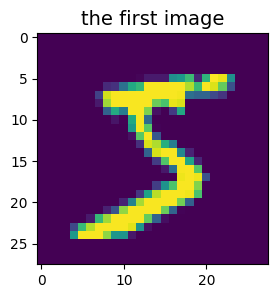

In [ ]:
plt.figure(figsize = (4,3))
plt.imshow(image_1) # lets see how the first image looks like
plt.title("the first image")

There are 70,000 images, and each image has 784 features. This is because each image is 28 × 28 pixels, and each feature
simply represents one pixel’s intensity, from 0 (white) to 255 (black). Let’s take a peek at one digit from the dataset
(Figure 3-1). All we need to do is grab an instance’s feature vector, reshape it to a 28 × 28 array, and display it using
Matplotlib’s imshow() function. We use cmap=
"binary" to get a grayscale color map where 0 is white and 255 is
black:

In [ ]:
# This gives the number of unique labels (10, for digits 0–9).
print(f"the length of the labels(y) : {len(set(y))}")
# that means going from 0 - 9

the length of the labels(y) : 10


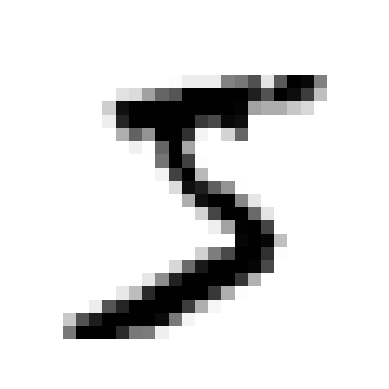

In [ ]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
  image = image_data.reshape(28,28)
  plt.imshow(image, cmap = "binary")
  plt.axis(False)

some_digit = X[0] # checking the image based on the index number
plot_digit(some_digit)
plt.show()

* now this above second image or the index X[1] image it looks like 0 , and indeed that's  what the label tell us .

* To give you a feel for the complexity of the classification task, below code shows a few more images from the MNIST dataset.

* There’s quite a large variety of digit shapes. That said, the images are clean, well centered, not too rotated, and
the digits all have roughly the same size: this dataset will not require much preprocessing

1. Note :-
(real-world datasets aren’t
usually that friendly) , that they dont need preprocessing like this dataset .

* Note :- wait! before checking out the images ,  

1. You should always create a test set and set it aside before inspecting the data closely.

2. The MNIST dataset
returned by `fetch_openml()` is actually already split into a training set (the first 60,000 images) and a test set (the last
10,000 images)

In [ ]:
# creating test and train sets
X_train , X_test , y_train, y_test = X[:60000] , X[60000:] , y[:60000] , y[60000:]

print(f"Train data size is {X_train.shape}")
print(f"Train target/labels size is {y_train.shape}")
print(f"Test data size is {X_test.shape}")
print(f"Test target/labels size is {y_test.shape}")

Train data size is (60000, 784)
Train target/labels size is (60000,)
Test data size is (10000, 784)
Test target/labels size is (10000,)


In [ ]:
# Let's check out our data and labels
X_train , y_train

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]),
 array(['5', '0', '4', ..., '5', '6', '8'], dtype=object))

The training set is already shuffled for us, which is good because this guarantees that all cross-validation folds will be
similar (we don’t want one fold to be missing some digits). Moreover, some learning algorithms are sensitive to the order
of the training instances, and they perform poorly if they get many similar instances in a row. Shuffling the dataset
ensures that this won’t happen.⁠

Now the terms:

* idx – just a loop counter/index (short for "index"); as you iterate, it's 0, 1, 2, 3...

* enumerate(X[:100]) – takes the first 100 images and gives you both the index (idx) and the actual image (image_data) at each step, instead of just the image.

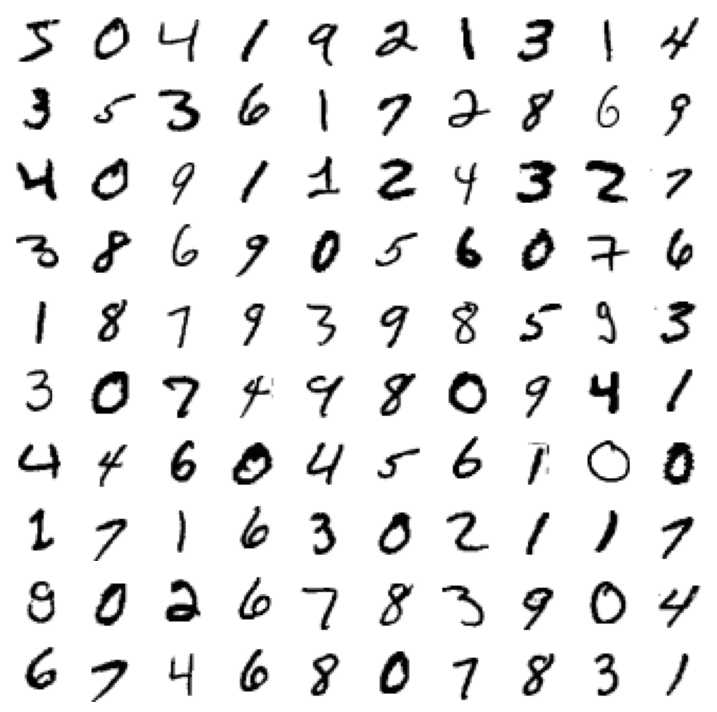

In [ ]:
# extra code
plt.figure(figsize = (9,9))
for idx , image_data in enumerate(X[:100]) : # X[:100] means starting 100 images
  plt.subplot(10, 10 , idx +1)
  plot_digit(image_data)
plt.show()

## 1.Training a Binary Classifier

Let’s simplify the problem for now and only try to identify one digit—for example, the number 5. This “5-detector” will
be an example of a binary classifier, capable of distinguishing between just two classes, 5 and non-5. First we’ll create
the target vectors for this classification task

In [ ]:
y_train_5 = (y_train == '5') # True for all 5s  ,False for all other digits
y_test_5 = (y_test == '5')

Now let’s pick a `classifier` and train it. A good place to start is with a `stochastic gradient descent (SGD , or stochastic GD)
classifier `, using Scikit-Learn’s `SGDClassifier class` . This classifier is capable of handling very large datasets
efficiently. This is in part because SGD deals with training instances independently, one at a time, which also makes SGD
well suited for online learning, as you will see later. Let’s create an SGDClassifier and train it on the whole training
set:

### 1.1 Selection of the model class

In [ ]:
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state = 42)
sgd_clf.fit(X_train , y_train_5)

SGDClassifier(random_state=42)

### 1.2 predicting

* Predicting on the image parameter(some_digit) we created earlier .

* can change the some_digit's value to any index no. and then use it below

In [ ]:
# Now we can use it to detect images of the number 5
sgd_clf.predict([some_digit])
# means predicting the number based on the X_train set and
# matching it with the y_train_5 means only '5' digit should be called True if match , rest false and
# using the image called some_digit defined in above cells and i did chnaged the index number to 0 which was actually '5' image.
# so it its true

array([ True])

* The classifier guesses that this image represents a 5 (True). Looks like it guessed right in this particular case! Now, let’s
evaluate this model’s performance.

## 2.Performance Measures

Evaluating a classifier is often significantly trickier than evaluating a regressor, so we will spend a large part of this
chapter on this topic. There are many performance measures available, so grab another coffee and get ready to learn a
bunch of new concepts and acronyms!

### 2.1 Measuring Accuracy Using Cross-Validation

A good way to evaluate a model is to use cross-validation, just as you did in Chapter 2. Let’s use the `cross_val_score()` function to evaluate our SGDClassifier model, using `k-fold` cross-validation with three folds.
Remember that k-fold cross-validation means splitting the training set into k folds (in this case, three), then training the
model k times, holding out a different fold each time for evaluation (see Chapter 2):

In [ ]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf , X_train , y_train_5 , cv =3 , scoring = "accuracy")
# sgd_clf is the instance i created earlier for the model class SGDClassifier
# X_train is the training data
# y_train_5 is the parameter i created earlier and here it means that it's equal to '5' only digit images .
# also y_train_5 will be on train set
# cv = 3 # means trianing set split into 3 folds and 2 folds will be used for trainign and 1 for evaluaitng , each cv will be different
# scoring here means based on accuracy we will see which fold performed betetr



array([0.95035, 0.96035, 0.9604 ])

Above 95% accuracy (ratio of correct predictions) on all cross-validation folds? This looks amazing, doesn’t it?
Well, before you get too excited, let’s look at a dummy classifier that just classifies every single image in the most
frequent class, which in this case is the negative class (i.e., non-5):

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier() # new instance , new class for dummy , using for dummy checking
dummy_clf.fit(X_train , y_train_5)
print(any(dummy_clf.predict(X_train))) # prints False : no 5s detected.


False


Can you guess this model’s accuracy? Let’s find out:

In [ ]:
cross_val_score(dummy_clf , X_train , y_train_5 ,cv = 3 , scoring = "accuracy")


array([0.90965, 0.90965, 0.90965])

* That’s right, it has over 90% accuracy! This is simply because only about 10% of the images are 5s, so if you always
guess that an image is not a 5, you will be right about 90% of the time. Beats Nostradamus.

* This demonstrates why `accuracy` is generally `not` the preferred performance measure for classifiers, especially when you
are dealing with skewed datasets (i.e., when some classes are much more frequent than others). A much better way to
evaluate the performance of a classifier is to look at the confusion matrix (CM).

### 2.2 IMPLEMENTING CROSS-VALIDATION

Occasionally you will need more control over the cross-validation process than what Scikit-Learn provides off the
shelf. In these cases, you can implement cross-validation yourself. The following code does roughly the same thing
as Scikit-Learn’s `cross_val_score()` function, and it prints the same result:


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits = 3) # adds shuffle = True if the dataset is not already shuffled

for train_index , test_index in skfolds.split(X_train, y_train_5):
  clone_clf =clone(sgd_clf)

  X_train_folds = X_train[train_index]
  y_train_folds = y_train_5[train_index]
  X_test_fold = X_train[test_index]
  y_test_fold = y_train_5[test_index]

  clone_clf.fit(X_train_folds, y_train_folds)
  y_pred = clone_clf.predict(X_test_fold)
  n_correct = sum(y_pred == y_test_fold)
  print(n_correct / len(y_pred)) # prints 0.95035 , 0.96035 and 0.9604

0.95035
0.96035
0.9604


The StratifiedKFold class performs stratified sampling (as explained in Chapter 2) to produce folds that
contain a representative ratio of each class. At each iteration the code creates a clone of the classifier, trains that
clone on the training folds, and makes predictions on the test fold. Then it counts the number of correct predictions
and outputs the ratio of correct predictions.

### 2.3 Confusing Matrices

1. The general idea of a confusion matrix is to count the number of times instances of class A are classified as class B, for
all A/B pairs. For example, to know the number of times the classifier confused images of 8s with 0s, you would look at
row #8, column #0 of the confusion matrix.


2. To compute the confusion matrix, you first need to have a set of predictions so that they can be compared to the actual
targets. You could make predictions on the test set, but it’s best to keep that untouched for now (remember that you want
to use the test set only at the very end of your project, once you have a classifier that you are ready to launch). Instead,
you can use the `cross_val_predict()` function:

In [ ]:
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5 , cv = 3)

y_train_pred[:10]

array([ True, False, False, False, False, False, False, False, False,
       False])

Just like the `cross_val_score() ` function, `cross_val_predict()` performs k-fold cross-validation, but instead of
returning the evaluation scores, it returns the predictions made on each test fold. This means that you get a clean
prediction for each instance in the training set (by “clean” I mean “out-of-sample”: the model makes predictions on data
that it never saw during training).

Now you are ready to get the confusion matrix using the confusion
_
matrix() function. Just pass it the target classes
`(y_train_5)` and the predicted classes `(y_train_pred)`:

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_train_5 , y_train_pred)
cm

array([[53892,   687],
       [ 1891,  3530]])

Each row in a confusion matrix represents an actual class, while each column represents a predicted class. The first row
of this matrix considers non-5 images (the negative class): 53,892 of them were correctly classified as non-5s (they are
called true negatives), while the remaining 687 were wrongly classified as 5s (false positives, also called type I errors).
The second row considers the images of 5s (the positive class): 1,891 were wrongly classified as non-5s (false negatives,
also called type II errors), while the remaining 3,530 were correctly classified as 5s (true positives). A perfect classifier
would only have true positives and true negatives, so its confusion matrix would have nonzero values only on its main
diagonal (top left to bottom right):

In [ ]:
y_train_perfect_predicitions = y_train_5 # pretend we reached perfection
confusion_matrix(y_train_5 , y_train_perfect_predicitions)

array([[54579,     0],
       [    0,  5421]])

### 2.4 Precision and Recall

Scikit-Learn provides several functions to compute classifier metrics, including precision and recall:


In [ ]:
from sklearn.metrics import precision_score , recall_score
precision_score(y_train_5 , y_train_pred) # == 3530 / (687 +3530)

0.8370879772350012

In [ ]:
recall_score(y_train_5 , y_train_pred) # == 3530 / (1891 + 3530)


0.6511713705958311

* Now our 5-detector does not look as shiny as it did when we looked at its accuracy. When it claims an image represents a
5, it is correct only 83.7% of the time. Moreover, it only detects 65.1% of the 5s.


### 2.5 F1 - Score


* It is often convenient to combine precision and recall into a single metric called the F1 score, especially when you need a
single metric to compare two classifiers. The F1 score is the harmonic mean of precision and recall (Equation 3-3).
Whereas the regular mean treats all values equally, the harmonic mean gives much more weight to low values. As a
result, the classifier will only get a high F1 score if both recall and precision are high.

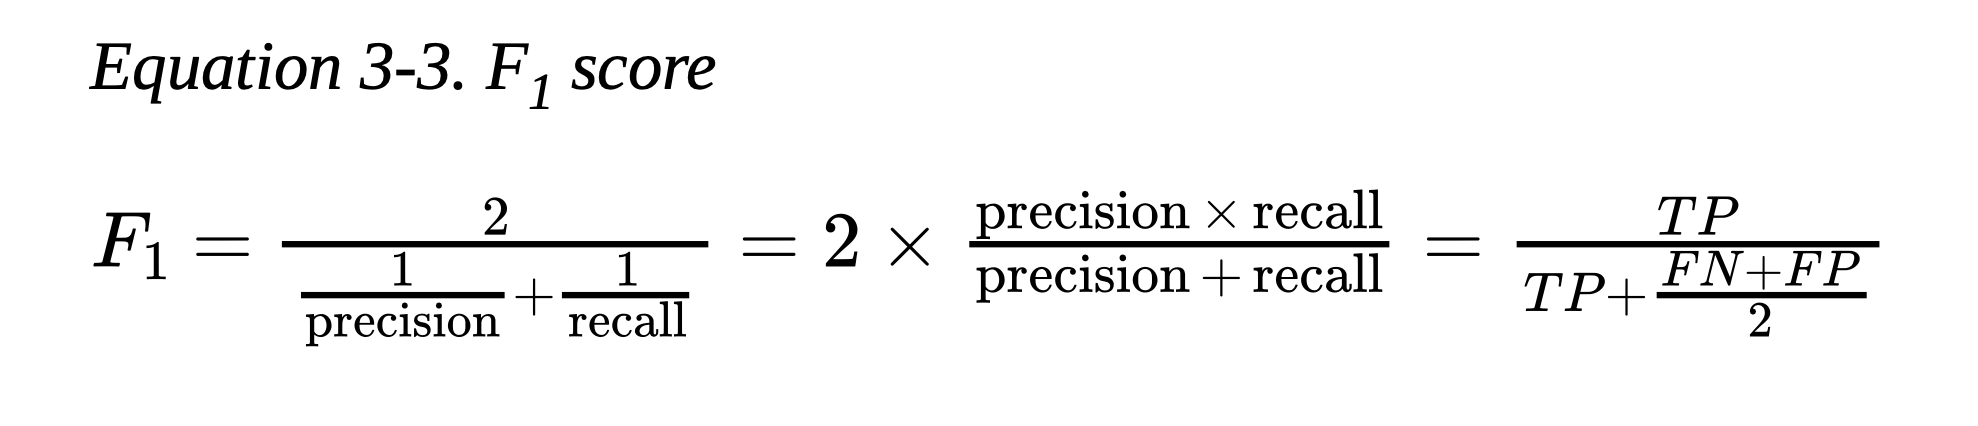

To compute the F1 score, simply call the `f1_score()` function:

In [ ]:
from sklearn.metrics import f1_score
f1_score(y_train_5 , y_train_pred)

0.7325171197343847

The F1 score favors classifiers that have similar precision and recall. This is not always what you want: in some contexts
you mostly care about precision, and in other contexts you really care about recall. For example, if you trained a classifier
to detect videos that are safe for kids, you would probably prefer a classifier that rejects many good videos (low recall)
but keeps only safe ones (high precision), rather than a classifier that has a much higher recall but lets a few really bad
videos show up in your product (in such cases, you may even want to add a human pipeline to check the classifier’s video
selection). On the other hand, suppose you train a classifier to detect shoplifters in surveillance images: it is probably fine
if your classifier only has 30% precision as long as it has 99% recall. Sure, the security guards will get a few false alerts,
but almost all shoplifters will get caught. Similarly, medical diagnosis usually requires a high recall to avoid missing
anything important. False positives can be ruled out by follow-up medical tests.

Unfortunately, you can’t have it both ways: increasing precision reduces recall, and vice versa. This is called the
precision/recall trade-off.

### 2.6 The Precision/Recall Trade - Off

* To understand this trade-off, let’s look at how the SGDClassifier makes its classification decisions. For each instance,
it computes a score based on a decision function. If that score is greater than a threshold, it assigns the instance to the
positive class; otherwise it assigns it to the negative class. Figure 3-4 shows a few digits positioned from the lowest score
on the left to the highest score on the right. Suppose the decision threshold is positioned at the central arrow (between the
two 5s): you will find 4 true positives (actual 5s) on the right of that threshold, and 1 false positive (actually a 6).

* Therefore, with that threshold, the precision is 80% (4 out of 5). But out of 6 actual 5s, the classifier only detects 4, so the
recall is 67% (4 out of 6). If you raise the threshold (move it to the arrow on the right), the false positive (the 6) becomes
a true negative, thereby increasing the precision (up to 100% in this case), but one true positive becomes a false negative,
decreasing recall down to 50%. Conversely, lowering the threshold increases recall and reduces precision.

* SGD - Updates weights using the gradient of the loss for a (mini-)batch, scaled by a fixed learning rate:

` weight = weight - lr * gradient `

In [ ]:
y_scores = sgd_clf.decision_function([some_digit])
y_scores

array([2164.22030239])

In [ ]:
threshold = 0
y_some_digit_pred = (y_scores  > threshold )
y_some_digit_pred

array([ True])

1. sgd_clf.decision_function([some_digit]) — instead of a plain True/False prediction, this gives you the raw score the model computed for that instance (here, 2164.22). Higher score = more confident it's a "5"; lower/negative = more confident it's "not a 5".

2. threshold = 0 then y_scores > threshold — this manually recreates what predict() does by default: anything with a score above 0 gets classified True (is a 5). Since 2164.22 > 0, you get True — same result predict() would've given.


3. This shows you the mechanism behind predict(): it's really just "score vs. threshold," and by default sklearn uses 0 as that cutoff. The point of exposing decision_function() is that you're not stuck with that default — you can raise or lower the threshold yourself to trade off precision vs. recall (e.g. raising it to 3000 makes the classifier more "picky," so it now misses this same digit — you'll see that in the next block).

* In short: decision_function = raw confidence score, predict() = that score compared to a hidden threshold (0). Exposing the score lets you set your own threshold instead.

In [ ]:
"""
The SGDClassifier uses a threshold equal to 0,
so the preceding code returns the same result as the predict()
method (i.e., True). Let’s raise the threshold:
"""

threshold = 3000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False])

"""
This confirms that raising the threshold decreases recall. The image actually represents a 5, and the classifier detects it
when the threshold is 0, but it misses it when the threshold is increased to 3,000.
"""

"""
How do you decide which threshold to use? One option is to use the `cross_val_predict()` function to get the scores of all instances in the training set, but this time specify that you want to return decision scores instead of predictions
"""

In [ ]:
y_scores = cross_val_predict(sgd_clf , X_train , y_train_5 , cv =3,
                             method = "decision_function")


y_scores

array([  1200.93051237, -26883.79202424, -33072.03475406, ...,
        13272.12718981,  -7258.47203373, -16877.50840447])

With these scores, use the `precision_recall_curve() `function to compute precision and recall for all possible
thresholds (the function adds a last precision of 1 and a last recall of 0, corresponding to an infinite threshold):

In [ ]:
from sklearn.metrics import precision_recall_curve
precisions , recalls , thresholds = precision_recall_curve(y_train_5, y_scores)


Finally, use Matplotlib to plot precision and recall as functions of the threshold value (Figure 3-5). Let’s show the
threshold of 3,000 we selected:

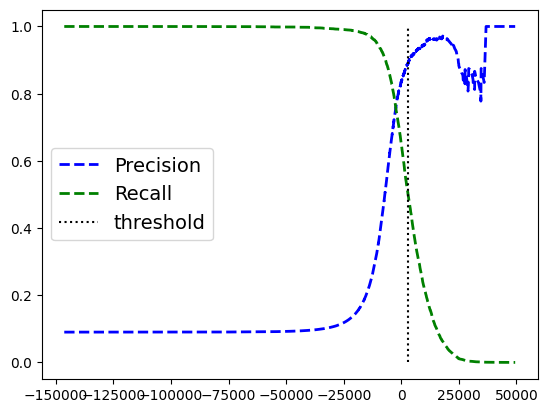

In [ ]:
plt.plot(thresholds, precisions[:-1], "b--" , label = "Precision" , linewidth = 2 )
plt.plot(thresholds, recalls[:-1], "g--" , label = "Recall", linewidth = 2)
plt.vlines(threshold, 0, 1, "k" , "dotted", label = "threshold")
# # beautify the figure: add grid, legend, axis, labels, and circles.
plt.legend()
plt.show()


Also, vlines() doesn't actually take x/y as parameter names — its signature is vlines(x, ymin, ymax, colors=..., linestyles=..., label=...)

In [ ]:
idx = np.argmin(np.abs(thresholds - 3000))
print(idx, thresholds[idx], recalls[idx], precisions[idx])

56978 3001.5895682301107 0.4967718133185759 0.8911317008603574


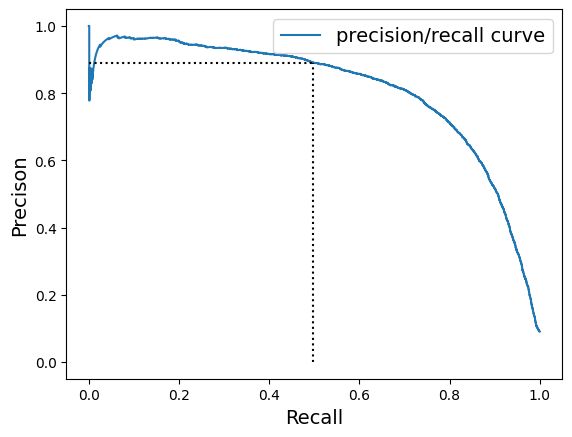

In [ ]:
plt.plot(recalls , precisions , label = "precision/recall curve")
plt.plot([recalls[idx], recalls[idx]], [0, precisions[idx]], "k:")
plt.plot([0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.xlabel("Recall")
plt.ylabel("Precison")
plt.legend()
plt.show()

In [ ]:
thresholds.min() , thresholds.max()

(np.float64(-146348.56726173862), np.float64(49441.437659047755))

* You can see that precision really starts to fall sharply at around 80% recall. You will probably want to select a
precision/recall trade-off just before that drop—for example, at around 60% recall. But of course, the choice depends on
your project.


* Suppose you decide to aim for 90% precision. You could use the first plot to find the threshold you need to use, but that’s
not very precise. Alternatively, you can search for the lowest threshold that gives you at least 90% precision. For this, you
can use the NumPy array’s argmax() method. This returns the first index of the maximum value, which in this case
means the first True value:

* Argmax() - Returns the index of the first True (or largest value) in an array — but if none are True, it silently returns 0 instead of erroring.

In [ ]:
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
threshold_for_90_precision

np.float64(3370.0194991439557)

* To make predictions (on the training set for now), instead of calling the classifier’s predict() method, you can run this
code:

In [ ]:
y_train_pred_90 = (y_scores >= threshold_for_90_precision)
y_train_pred_90

array([False, False, False, ...,  True, False, False])

In [ ]:
# let's check these predicition's precision and recall
precision_score(y_train_5, y_train_pred_90)

0.9000345901072293

In [ ]:
recall_at_90_precision = recall_score(y_train_5, y_train_pred_90 )
recall_at_90_precision

0.4799852425751706

* Great, you have a 90% precision classifier! As you can see, it is fairly easy to create a classifier with virtually any
precision you want: just set a high enough threshold, and you’re done. But wait, not so fast: a high-precision classifier is
not very useful if its recall is too low! For many applications, 48% recall wouldn’t be great at all.



#### Tip : If someone says,
“Let’s reach 99% precision”
, you should ask,
“At what recall?”

## 3.The ROC Curve (The receiver operating characteristic)

The receiver operating characteristic (ROC) curve is another common tool used with binary classifiers. It is very similar
to the precision/recall curve, but instead of plotting precision versus recall, the ROC curve plots the true positive rate
(another name for recall) against the false positive rate (FPR). The FPR (also called the fall-out) is the ratio of negative
instances that are incorrectly classified as positive. It is equal to 1 – the true negative rate (TNR), which is the ratio of
negative instances that are correctly classified as negative. The TNR is also called specificity. Hence, the ROC curve plots
sensitivity (recall) versus 1 – specificity.



* To plot the ROC curve, you first use the roc_curve() function to compute the TPR and FPR for various threshold values:

In [ ]:
from sklearn.metrics import roc_curve
fpr, tpr , thresholds = roc_curve(y_train_5 , y_scores)


Then you can plot the FPR against the TPR using Matplotlib. The following code produces the plot in Figure 3-7. To find
the point that corresponds to 90% precision, we need to look for the index of the desired threshold. Since thresholds are
listed in decreasing order in this case, we use <= instead of >= on the first line:

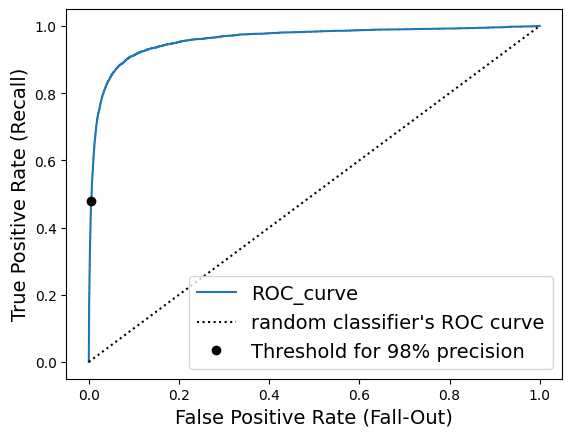

In [ ]:
idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90 , fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]
plt.plot(fpr, tpr,  label ="ROC_curve")
plt.plot([0,1] , [0,1] , 'k:' , label = "random classifier's ROC curve")
plt.plot([fpr_90], [tpr_90] , "ko" , label = "Threshold for 98% precision")
plt.xlabel("False Positive Rate (Fall-Out)")
plt.ylabel("True Positive Rate (Recall)")
plt.axis(True)
plt.legend()
plt.show()

1.[0,1], [0,1] — this is just two points: (0,0) and (1,1). Plotting a line between them draws the diagonal from bottom-left to top-right.

2. 'k:' — this is matplotlib's shorthand format string, combining two things in one string:

   * k = color black (matplotlib's single-letter color codes: k=black, b=blue, g=green, r=red, etc.)

   * : = line style dotted

   * So 'k:' = "dotted black line." You're choosing this yourself — it's not fixed, just a style choice to visually distinguish the baseline from your actual ROC curve.
3. label=... — just the text that shows up in the legend for this line.

4. [fpr_90], [tpr_90] — single x and y values wrapped in lists (matplotlib needs iterables, even for one point).

5. "ko" — same idea as before: k = black, but o here means marker style "circle" (not a line style). So this plots a single black dot instead of a line — makes sense since you're marking one specific point on the curve, not drawing a segment.

   * This just visually marks where on the ROC curve your chosen threshold lands, same purpose as the earlier precision/recall point-marking you did.

* Once again there is a trade-off: the higher the recall (TPR), the more false positives (FPR) the classifier produces. The
dotted line represents the ROC curve of a purely random classifier; a good classifier stays as far away from that line as
possible (toward the top-left corner).

### 3.1 ROC-AUC (AUC is area under curve)


* One way to compare classifiers is to measure the area under the curve (AUC). A perfect classifier will have a ROC AUC
equal to 1, whereas a purely random classifier will have a ROC AUC equal to 0.5. Scikit-Learn provides a function to
estimate the ROC AUC:

In [ ]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5 ,y_scores)

np.float64(0.9604938554008616)

#### TIP
Since the ROC curve is so similar to the precision/recall (PR) curve, you may wonder how to decide which one to
use. As a rule of thumb, you should prefer the PR curve whenever the positive class is rare or when you care more
about the false positives than the false negatives. Otherwise, use the ROC curve. For example, looking at the
previous ROC curve (and the ROC AUC score), you may think that the classifier is really good. But this is mostly
because there are few positives (5s) compared to the negatives (non-5s). In contrast, the PR curve makes it clear that
the classifier has room for improvement: the curve could really be closer to the top-right corner

* let's now create a RandomForestClassifier , whose PR curve and F1 score wwe can compare to those of SGDClassifier:

In [ ]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state = 42)
forest_clf

RandomForestClassifier(random_state=42)

The precision_recall_curve() function expects labels and scores for each instance, so we need to train the
random forest classifier and make it assign a score to each instance. But the RandomForestClassifier class does not
have a decision_function() method, due to the way it works (we will cover this in Chapter 6). Luckily, it has a predict_proba() method that returns estimated class probabilities for each instance, and we can just use the
probability of the positive class as a score, so precision_recall_curve() will work.4 We can call the cross_val_predict() function to train the RandomForestClassifier using cross-validation and make it predict class
probabilities for every image as follows:

In [ ]:
y_probas_forest = cross_val_predict(forest_clf , X_train , y_train_5 , cv = 3
                                    , method =  "predict_proba")
y_probas_forest

array([[0.11, 0.89],
       [0.99, 0.01],
       [0.96, 0.04],
       ...,
       [0.02, 0.98],
       [0.92, 0.08],
       [0.94, 0.06]])

In [ ]:
# Let’s look at the estimated class probabilities for the first two images in the training set:
y_probas_forest[:2]


array([[0.11, 0.89],
       [0.99, 0.01]])

"""
The model predicts that the first image is positive with 89% probability, and it predicts that the second image is negative
with 99% probability. Since each image is either positive or negative, the estimated probabilities in each row add up to
100%.
"""

#### WARNING
These are estimated probabilities, not actual probabilities. For example, if you look at all the images that the model
classified as positive with an estimated probability between 50% and 60%, roughly 94% of them are actually
positive. So, the model’s estimated probabilities were much too low in this case—but models can be overconfident as
well. The CalibratedClassifierCV class from the sklearn.calibration package can calibrate the
estimated probabilities using cross-validation, making them much closer to actual probabilities (see the notebook for
a code example). This is important in some scenarios, such as medical diagnosis, financial risk assessment, or fraud
detection

The second column contains the estimated probabilities for the positive class, so let’s pass them to the
`precision_recall_curve()` function:

In [ ]:
y_scores_forest = y_probas_forest[:, 1]
precisions_forest , recall_forest, thresholds_forest = precision_recall_curve(y_train_5 , y_scores_forest)


* Now Comparing PR curves: the random forest classifier is superior to the SGD classifier because its PR curve is much closer to the top-right corner, and it has a greater AUC .

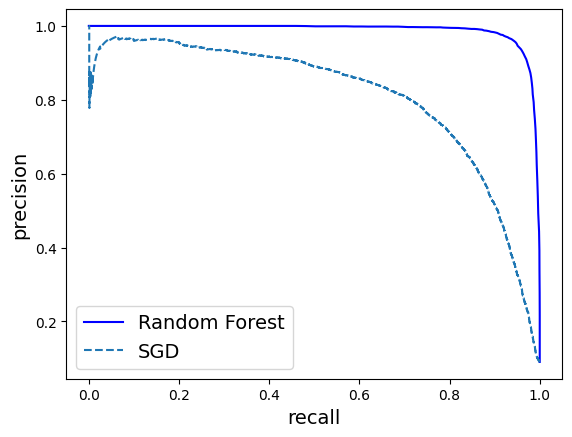

In [ ]:
# Now we’re ready to plot the PR curve.
# It is useful to plot the first PR curve
# as well to see how they compare

plt.plot(recall_forest ,precisions_forest , "b-" ,
         label = "Random Forest")
plt.plot(recalls , precisions, "--"  , label = "SGD")
plt.xlabel("recall")
plt.ylabel("precision")
plt.legend()
plt.show()

As you can see in the above plot, the RandomForestClassifier’s PR curve looks much better than the
SGDClassifier’s: it comes much closer to the top-right corner. Its F1 score and ROC AUC score are also significantly
better:

In [ ]:
y_train_pred_forest = y_probas_forest[:, 1] >= 0.5 # positive proba >= 50%
print(y_train_pred_forest[:10])

[ True False False False False False False False False False]


In [ ]:
f1_score(y_train_5 , y_train_pred_forest)

0.9274509803921569

In [ ]:
roc_auc_score(y_train_5, y_scores_forest)


np.float64(0.9983436731328145)

* Try measuring the precision and recall scores: you should find about 99.0% precision and 87.3% recall. Not too bad!

* You now know how to train binary classifiers, choose the appropriate metric for your task, evaluate your classifiers using
cross-validation, select the precision/recall trade-off that fits your needs, and use several metrics and curves to compare
various models. You’re ready to try to detect more than just the 5s.

## 4.Multiclass Classification

In [ ]:
from sklearn.svm import SVC

svm_clf = SVC(random_state = 42 )
svm_clf.fit(X_train[:2000], y_train[:2000]) # y_train, not y_train_5


SVC(random_state=42)

That was easy! We trained the SVC using the original target classes from 0 to 9 (y_
train), instead of the 5-versus-the-
rest target classes (y_
train
_
5). Since there are 10 classes (i.e., more than 2), Scikit-Learn used the OvO strategy and
trained 45 binary classifiers. Now let’s make a prediction on an image:

In [ ]:
svm_clf.predict([some_digit])

array(['5'], dtype=object)

That’s correct! This code actually made 45 predictions—one per pair of classes—and it selected the class that won the
most duels.⁠
5 If you call the decision
_
function() method, you will see that it returns 10 scores per instance: one per
class. Each class gets a score equal to the number of won duels plus or minus a small tweak (max ±0.33) to break ties,
based on the classifier scores

In [ ]:
# testing what said above that means using the decision_function
some_digit_scores = svm_clf.decision_function([some_digit])
some_digit_scores.round(2)
# the highest score here is 9.3 and its indeed the one corresponding to class 5

array([[ 3.79,  0.73,  6.06,  8.3 , -0.29,  9.3 ,  1.75,  2.77,  7.21,
         4.82]])

In [ ]:
class_id = some_digit_scores.argmax()
class_id

np.int64(5)

When a classifier is trained, it stores the list of target classes in its `classes_ attribute` , ordered by value. In the case of
MNIST, the index of each class in the classes
_ array conveniently matches the class itself (e.g., the class at index 5
happens to be class '5'), but in general you won’t be so lucky; you will need to look up the class label like this:

In [ ]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

#### note: If you want to force Scikit-Learn to use one-versus-one or one-versus-the-rest, you can use the OneVsOneClassifier
or OneVsRestClassifier classes. Simply create an instance and pass a classifier to its constructor (it doesn’t even
have to be a binary classifier). For example, this code creates a multiclass classifier using the OvR strategy, based on an
SVC:

In [ ]:
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = OneVsRestClassifier(SVC(random_state = 42))
ovr_clf.fit(X_train[:2000] , y_train[:2000])


OneVsRestClassifier(estimator=SVC(random_state=42))

In [ ]:
# Let’s make a prediction, and check the number of trained classifiers:
ovr_clf.predict([some_digit])


array(['5'], dtype='<U1')

* len(ovr_clf.estimators_) means :
It means OneVsRestClassifier trained 10 separate binary SVC models internally — one per digit class (0 vs rest, 1 vs rest, 2 vs rest, ..., 9 vs rest). Each one specializes in distinguishing its class from all others, and when you call .predict(), it runs the input through all 10 and picks whichever one gives the highest confidence score.

In [ ]:
len(ovr_clf.estimators_)

10

In [ ]:
# training an SGDClassifier on a multiclass dataset and using it to make predicitions is just as easy
sgd_clf = SGDClassifier(random_state = 42 )
print(sgd_clf)


SGDClassifier(random_state=42)


In [ ]:
sgd_clf.fit(X_train, y_train)
sgd_clf.predict([some_digit])

array(['3'], dtype='<U1')

Oops, that’s incorrect. Prediction errors do happen! This time Scikit-Learn used the OvR strategy under the hood: since
there are 10 classes, it trained 10 binary classifiers. The decision
_
function() method now returns one value per
class. Let’s look at the scores that the SGD classifier assigned to each class:

In [ ]:
sgd_clf.decision_function([some_digit]).round(1)

array([[-31893. , -34419.7,  -9530.6,   1823.7, -22320.1,  -1385.8,
        -26188.9, -16147.5,  -4604.4, -12050.8]])

You can see that the classifier is not very confident about its prediction: almost all scores are very negative, while class 3
has a score of +1,824, and class 5 is not too far behind at –1,386. Of course, you’ll want to evaluate this classifier on
more than one image. Since there are roughly the same number of images in each class, the accuracy metric is fine. As
usual, you can use the `cross_val_score()` function to evaluate the model:

In [ ]:
cross_val_score(sgd_clf,X_train , y_train , cv =3 , scoring = "accuracy")


array([0.87365, 0.85835, 0.8689 ])

It gets over 85.8% on all test folds. If you used a random classifier, you would get 10% accuracy, so this is not such a bad
score, but you can still do much better. Simply scaling the inputs (as discussed in Chapter 2) increases accuracy above
89.1%:

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler

StandardScaler()

In [ ]:
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))
# cross_val_score(sgd_clf,  X_train_scaled , y_train, cv = 3 , scoring = "accuracy" )
# array([0.8983, 0.891 , 0.9018])

## 5.Error Analysis

https://homl.info/checklist

* You’d explore data preparation options, try out multiple models, shortlist the best ones, fine-
tune their hyperparameters using GridSearchCV, and automate as much as possible

note :- here we be assuming that we have found a promising model and you want to find ways to improve it . One way to do this is to analyze the types of errors it makes.

1. First, look at the confusion matrix. For this, you first need to make predictions using the `cross_val_predict()`
function; then you can pass the labels and predictions to the `confusion_matrix()` function, just like you did earlier.
However, since there are now 10 classes instead of 2, the confusion matrix will contain quite a lot of numbers, and it may
be hard to read.

A colored diagram of the confusion matrix is much easier to analyze. To plot such a diagram, use the`
ConfusionMatrixDisplay.from
_predictions()` function like this:

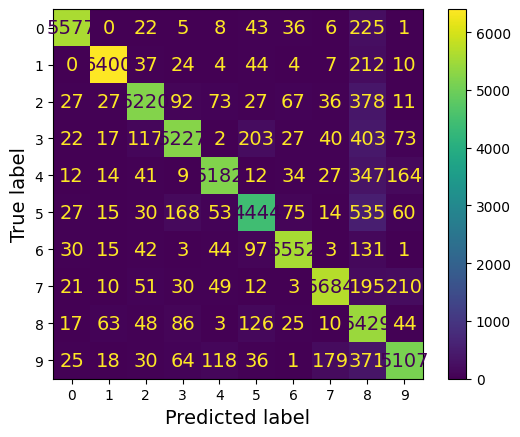

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred = cross_val_predict(sgd_clf, X_train_scaled , y_train , cv =3)
ConfusionMatrixDisplay.from_predictions(y_train , y_train_pred)
plt.show()

The problem: raw counts alone can mislead you.

* Look at row 5 (true label "5") in the left matrix: only 4444 correct predictions on the diagonal — noticeably lower than most other rows (5577, 6400, 5220, 5227...). Your first instinct might be "the model is bad at recognizing 5s."

* But that's not necessarily true — it could just be that there simply aren't as many 5s in the dataset to begin with. If class "5" only has ~5,000 total images while class "1" has ~6,700, then even a perfectly equal-quality model would naturally show a smaller number on the "5" diagonal, purely because there were fewer 5s to get right in the first place. Raw counts don't tell you whether that darker cell is "worse performance" or just "smaller sample size."

* The fix — normalize by row:
Instead of showing raw counts, divide every cell in a row by that row's total (i.e., the total number of actual "5" images). Now each cell shows a percentage: "of all the true 5s, what % were classified as each digit?" This removes the sample-size problem entirely, because percentages are relative to that class's own total, not to raw quantity.

* Look at the right matrix, row 5: only 82% correct — clearly lower than row 0 (94%), row 1 (95%), row 6 (94%), etc. Now you can say with confidence: the model genuinely struggles more with 5s specifically (not just "5 has fewer images") — you can also see where it's confusing them: 10% of true 5s got predicted as "8" (a real, meaningful pattern, not a sample-size artifact).

* So: normalize="true" divides by the row sum, turning raw counts into fair, comparable per-class percentages — that's what makes rows genuinely comparable to each other.

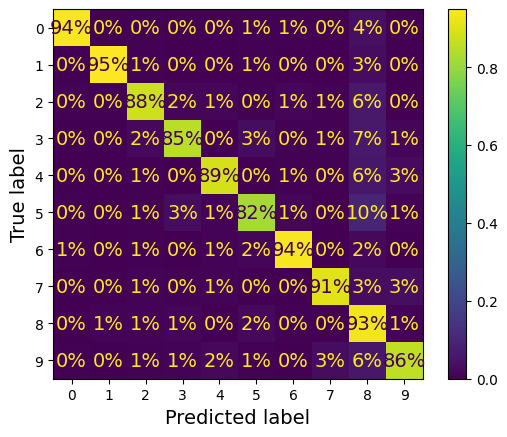

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_train , y_train_pred,
                                         normalize = "true",
                                         values_format = ".0%")
plt.show()

Now we can easily see that only 82% of the images of 5s were classified correctly. The most common error the model
made with images of 5s was to misclassify them as 8s: this happened for 10% of all 5s. But only 2% of 8s got
misclassified as 5s; confusion matrices are generally not symmetrical! If you look carefully, you will notice that many
digits have been misclassified as 8s, but this is not immediately obvious from this diagram. If you want to make the errors
stand out more, you can try putting zero weight on the correct predictions. The following code does just that and produces
the diagram on the left in Figure 3-10:

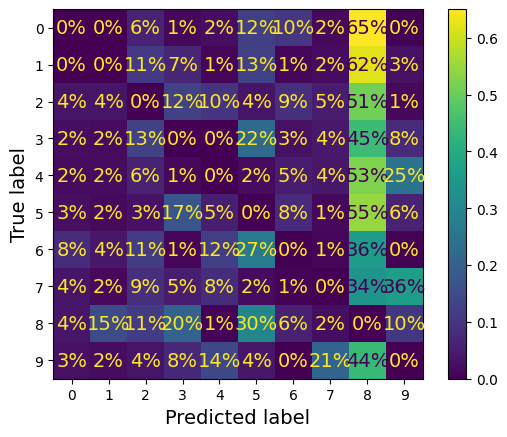

In [ ]:
"""
Simple way to think about it:

Correct predictions = weight 0 = erased from the picture.
Errors = weight 1 = the only thing left to look at.
Result: the color scale recalibrates to highlight error patterns
instead of being swamped by correct-prediction counts.
"""

sample_weight = (y_train_pred != y_train)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred,
                                         sample_weight = sample_weight,
                                         normalize ="true", values_format = ".0%")
plt.show()

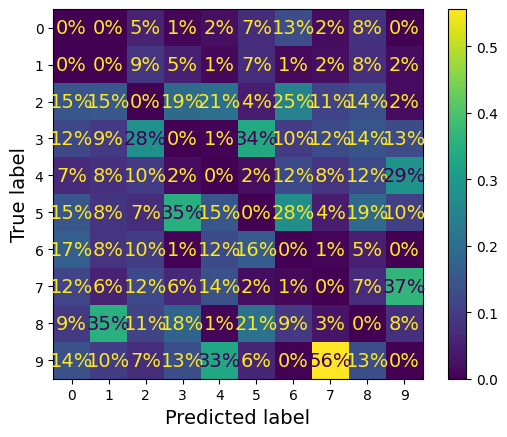

In [ ]:
sample_weight = (y_train_pred != y_train)
ConfusionMatrixDisplay.from_predictions(y_train , y_train_pred,
                                        sample_weight = sample_weight,
                                        normalize = "pred" , values_format = ".0%")


In [ ]:
cl_a , cl_b = '3' , '5'
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]
# plot all images in X_aa, X_ab, X_ba, X_bb in a confusion matrix style

## 6.Multilabel Classification

Until now, each instance has always been assigned to just one class. But in some cases you may want your classifier to
output multiple classes for each instance. Consider a face-recognition classifier: what should it do if it recognizes several
people in the same picture? It should attach one tag per person it recognizes. Say the classifier has been trained to
recognize three faces: Alice, Bob, and Charlie. Then when the classifier is shown a picture of Alice and Charlie, it should
output [True, False, True] (meaning “Alice yes, Bob no, Charlie yes”). Such a classification system that outputs
multiple binary tags is called a multilabel classification system.


We won’t go into face recognition just yet, but let’s look at a simpler example, just for illustration purposes:

In [ ]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= '7')
print(y_train_large[:5])
y_train_odd = (y_train.astype('int8') % 2 == 1)
print(y_train_odd[:5])

y_multilabel = np.c_[y_train_large, y_train_odd]
print(y_multilabel[:5])

knn_clf = KNeighborsClassifier()
print(knn_clf)
knn_clf.fit(X_train , y_multilabel)


[False False False False  True]
[ True False False  True  True]
[[False  True]
 [False False]
 [False False]
 [False  True]
 [ True  True]]
KNeighborsClassifier()


KNeighborsClassifier()

This code creates a y_
multilabel array containing two target labels for each digit image: the first indicates whether
the digit is large (7, 8, or 9), and the second indicates whether it is odd. Then the code creates a
KNeighborsClassifier instance, which supports multilabel classification (not all classifiers do), and trains this
model using the multiple targets array. Now you can make a prediction, and notice that it outputs two labels

In [ ]:
knn_clf.predict([some_digit])
# And it gets it right! The digit 5 is indeed not large (False) and odd (True).

array([[False,  True]])

There are many ways to evaluate a multilabel classifier, and selecting the right metric really depends on your project. One
approach is to measure the F1 score for each individual label (or any other binary classifier metric discussed earlier), then
simply compute the average score. The following code computes the average F1 score across all labels:

In [ ]:
y_train_knn_pred = cross_val_predict(knn_clf , X_train , y_multilabel , cv = 3)


In [ ]:
print(y_train_knn_pred[:10])

[[False  True]
 [False False]
 [False False]
 [False  True]
 [ True  True]
 [False False]
 [False  True]
 [False  True]
 [False  True]
 [False False]]


General pattern to remember: any sklearn metric function follows metric(y_true, y_pred, ...) — true values first, predictions second, always in that order. Extra keyword args (like average, cv, pos_label) just tune how the calculation is done, not what data goes in. Once you recognize that skeleton, most of these functions become predictable — you're not memorizing each one from scratch, just learning what extra options exist for each use case (single-label vs multilabel vs multiclass).

In [ ]:
# now let's get the f1 score
f1_score(y_multilabel , y_train_knn_pred , average ="macro")


0.9764102655606048

* Note(₹) :- the above approach assumes that all labels are equally important , which may  note be the case.

In particular, if you have many
more pictures of Alice than of Bob or Charlie, you may want to give more weight to the classifier’s score on pictures of
Alice. One simple option is to give each label a weight equal to its support (i.e., the number of instances with that target
label). To do this, simply set `average = "weighted"` when calling the `f1_score()` function.

If you wish to use a classifier that does not natively support multilabel classification, such as SVC, one possible strategy is
to train one model per label. However, this strategy may have a hard time capturing the dependencies between the labels.
For example, a large digit (7, 8, or 9) is twice more likely to be odd than even, but the classifier for the “odd” label does
not know what the classifier for the “large” label predicted. To solve this issue, the models can be organized in a chain:
when a model makes a prediction, it uses the input features plus all the predictions of the models that come before it in
the chain.


The good news is that Scikit-Learn has a class called `ClassifierChain` that does just that! By default it will use the
true labels for training, feeding each model the appropriate labels depending on their position in the chain. But if you set
the cv hyperparameter, it will use cross-validation to get “clean” (out-of-sample) predictions from each trained model for
every instance in the training set, and these predictions will then be used to train all the models later in the chain.

* Note(₹) :-
that the order of the classifiers in the chain may affect the final performance. Here’s an example showing how to create
and train a ClassifierChain using the cross-validation strategy. As earlier, we’ll just use the first 2,000 images in the
training set to speed things up:

In [ ]:
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(SVC(), cv = 3 , random_state = 42)

chain_clf.fit(X_train[:2000], y_multilabel[:2000])

ClassifierChain(base_estimator=SVC(), cv=3, random_state=42)

Now we can use this ClassifierChain to make predictions:

In [ ]:
chain_clf.predict([some_digit])

array([[0., 1.]])

## 7. multioutput - multiclass classification OR just multioutput classification


* It is a generalization of multilabel classification where each label can be multiclass (i.e., it can have more
than two possible values).

* To illustrate this, let’s build a system that removes noise from images. It will take as input a noisy digit image, and it will
(hopefully) output a clean digit image, represented as an array of pixel intensities, just like the MNIST images. Notice
that the classifier’s output is multilabel (one label per pixel) and each label can have multiple values (pixel intensity
ranges from 0 to 255). This is thus an example of a multioutput classification system.

* Note(₹) :-
The line between classification and regression is sometimes blurry, such as in this example. Arguably, predicting
pixel intensity is more akin to regression than to classification. Moreover, multioutput systems are not limited to
classification tasks; you could even have a system that outputs multiple labels per instance, including both class
labels and value labels.

Let’s start by creating the training and test sets by taking the MNIST images and adding noise to their pixel intensities,
using a random number generator’s integers() method. The target images will be the original images:

In [ ]:
import numpy as np
rng = np.random.default_rng(seed = 42)
noise_train = rng.integers(0 , 100, (len(X_train), 784))
#checking the noise (fake image)
# (extra integer values in all the images )
print(noise_train)

[[ 8 77 65 ... 63 12 12]
 [47 58  3 ... 45 96 60]
 [90 98  7 ... 50 53 75]
 ...
 [58 11 25 ... 92 83 71]
 [32 37 62 ... 61 28 93]
 [81 93 26 ... 73 40 55]]


In [ ]:
# adding up the noise and the real image and
# combining/mixing them together
X_train_mod = X_train + noise_train
print(X_train_mod)

[[ 8 77 65 ... 63 12 12]
 [47 58  3 ... 45 96 60]
 [90 98  7 ... 50 53 75]
 ...
 [58 11 25 ... 92 83 71]
 [32 37 62 ... 61 28 93]
 [81 93 26 ... 73 40 55]]


In [ ]:
# same as before, but now generating
#  noise for the test set instead of train
noise_test = rng.integers(0 , 100, (len(X_test) , 784 ))

# corrupting the test
# images the same way — adding the noise/static
X_test_mod = X_test + noise_test
print(X_test_mod)

[[40 52 66 ...  0 25 57]
 [14 96  7 ... 64 35 55]
 [76 22 15 ... 97 12 60]
 ...
 [54  7 33 ... 72 22 30]
 [20 64 82 ... 67 81 95]
 [82 44 59 ... 42 91 22]]


In [ ]:
y_train_mod = X_train
y_train_mod


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

Why this makes sense: earlier you built X_train_mod = clean image + random noise (the input). Now you're saying: "the target/label for that noisy input isn't a digit class like '5' — it's the clean image itself." So the model's job becomes: given a noisy image, output the clean image — i.e. denoising.

In [ ]:
# same explantion like above ,
# for having the output correct from the actual data
y_test_mod = X_test
y_test_mod

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

Let’s take a peek at the first image from the test set (Figure 3-12). Yes, we’re snooping on the test data, so you should be
frowning right now.

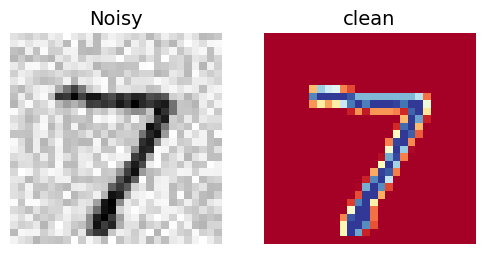

In [ ]:
plt.figure(figsize = (6,3))
plt.subplot(1,2,1)# plt.subplot(rows, cols, index)
plt.imshow(X_test_mod[0].reshape(28, 28),cmap = "binary")
plt.title("Noisy")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(y_test_mod[0].reshape(28,28) , cmap = plt.cm.RdYlBu)
plt.title("clean")
plt.axis("off")

plt.show()

Now let’s train the classifier and make it
clean up this image

In [ ]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[0]])

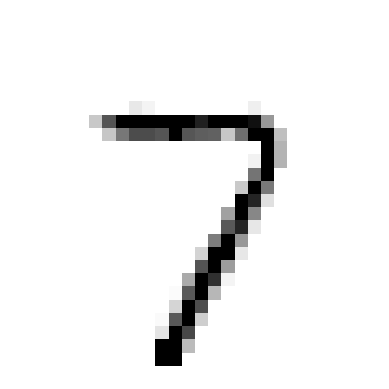

In [ ]:
plot_digit(clean_digit)
plt.show()

Looks close enough to the target! This concludes our tour of classification. You now know how to select good metrics for
classification tasks, pick the appropriate precision/recall trade-off, compare classifiers, and more generally build good
classification systems for a variety of tasks. In the next chapters, you’ll learn how all these machine learning models
you’ve been using actually work